# volatility-surface-svi: end-to-end demo

Runs the whole pipeline on the **bundled synthetic SPY-like chain** (`data/sample/`) in well under two minutes:
clean quotes → parity forwards → Black-76 implied vols → raw SVI, constrained SVI and SSVI →
static-arbitrage audit → Dupire local vol → barrier options under local vol vs flat Black-Scholes.

The README numbers come from the real SPY snapshot of 2026-06-03 (raw quotes not redistributed);
`python scripts/run_results.py` regenerates everything shown here with the full settings.

In [1]:
import time
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from volsurf.data import load_snapshot
from volsurf.pipeline import StudyConfig, run_study
from volsurf.plots import plot_all
from volsurf.report import md_arbitrage_table, md_barrier_table, md_fit_table

warnings.filterwarnings("ignore", message="Values in x were outside bounds")
pd.set_option("display.width", 160)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
t_start = time.perf_counter()

## 1. Frozen snapshot and documented cleaning
Every filter is logged with the number of quotes it keeps (two-sided quote, OTM, minimum bid, implied vol exists,
|delta| floor, vol spread).

In [2]:
snap = load_snapshot(ROOT / "data/sample/spy_like_20260603.json")
print(snap.meta.description)
print(f"valuation time {snap.meta.valuation_time}, r = {snap.meta.rate:.4%} (cc)")
print(f"dividends: {snap.meta.dividends}")
snap.filter_log

Synthetic option chain generated by scripts/make_sample.py from constrained-SVI fits of the real SPY snapshot of 2026-06-03 (same expiries, forwards, discounting, strike coverage, quote noise and bid-ask widths). Not market data.
valuation time 2026-06-03 14:35:53+00:00, r = 3.6974% (cc)
dividends: (Dividend(ex_date=datetime.date(2026, 6, 18), amount=1.903516, source='SSGA 2026 SPDR distribution schedule (dates); amount as published by SSGA / Wall Street Horizon'), Dividend(ex_date=datetime.date(2026, 9, 18), amount=1.888834, source='SSGA 2026 SPDR distribution schedule (dates); amount as published by SSGA / Wall Street Horizon'))


,expiry,T_days,raw,two_sided,otm,min_bid,iv_exists,delta,vol_spread,final
0,2026-07-02,29.225081,358,358,178,162,162,159,159,159
1,2026-07-31,58.225081,400,400,200,200,200,198,198,198
2,2026-08-31,89.225081,430,430,215,215,215,215,215,215
3,2026-11-30,180.266748,426,426,213,213,213,213,213,213


## 2. Calibration, arbitrage audit, local vol and barriers
Light settings (fewer Monte-Carlo paths and repeated runs) keep the demo fast; the published study uses
`StudyConfig()` (400k paths, 4 steps per day).

In [3]:
cfg = StudyConfig(n_paths=100_000, steps_per_day=2, n_timing_runs=1, n_noise_runs=3)
res = run_study(snap, cfg)
print(md_fit_table(res))

| Expiry | T (days) | Quotes | ATM vol | RMSE SVI raw | RMSE SVI constrained | RMSE SSVI | Half bid-ask |
|---|---:|---:|---:|---:|---:|---:|---:|
| 2026-07-02 | 29 | 159 | 13.29% | 0.20 | 0.20 | 1.31 | 0.037 |
| 2026-07-31 | 58 | 198 | 14.39% | 0.12 | 0.12 | 1.34 | 0.026 |
| 2026-08-31 | 89 | 215 | 15.15% | 0.13 | 0.13 | 1.41 | 0.024 |
| 2026-11-30 | 180 | 213 | 16.59% | 0.09 | 0.09 | 0.71 | 0.024 |


Implied-vol RMSE in vol points. Raw and constrained SVI fit each expiry to within a few tenths of a vol point;
SSVI uses one set of shape parameters for all expiries and pays for it in fit.

In [4]:
print(md_arbitrage_table(res))

| Model | Slices with g(k) < 0 | of which inside quoted range | Min g(k) | Negative-density points (price check) | Calendar crossings: quoted / extrapolated (grid points) |
|---|---:|---:|---:|---:|---:|
| SVI raw | 1 / 4 | 0 | -0.003 | 105 | 0 / 0 |
| SVI constrained | 0 / 4 | 0 | +0.000 | 0 | 0 / 0 |
| SSVI | 0 / 4 | 0 | +0.254 | 0 | 0 / 0 |


Butterfly arbitrage is checked twice, with Durrleman's g(k) and with the convexity of call prices in strike;
calendar arbitrage is the crossing of total-variance curves. Violations are split between the quoted strike range
and the extrapolated wings.

In [5]:
print(md_barrier_table(res))

| Barrier | DIP local vol | DIP BS strike vol | DIP BS barrier vol | LV - BS(strike) | Coupon effect p.a. | DOC local vol | DOC BS strike vol | DOC gap |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 75% | 1.14% | 0.00% | 2.09% | +1.14% | +4.7% | 3.41% | 3.41% | +0.2% |
| 80% | 1.53% | 0.07% | 2.72% | +1.46% | +6.0% | 3.41% | 3.41% | +0.0% |
| 85% | 1.97% | 0.48% | 3.30% | +1.49% | +6.1% | 3.39% | 3.41% | -0.6% |
| 90% | 2.39% | 1.60% | 3.62% | +0.78% | +3.2% | 3.28% | 3.40% | -3.6% |
| 95% | 2.69% | 2.62% | 3.43% | +0.08% | +0.3% | 2.78% | 3.04% | -8.4% |


Same paths, same forward curve (with SPY's cash dividends), two volatility models: the gap is model risk.
With a negative skew, local vol is higher near the barrier than the at-the-strike flat vol, so the down-and-in put
is dearer and the down-and-out call cheaper.

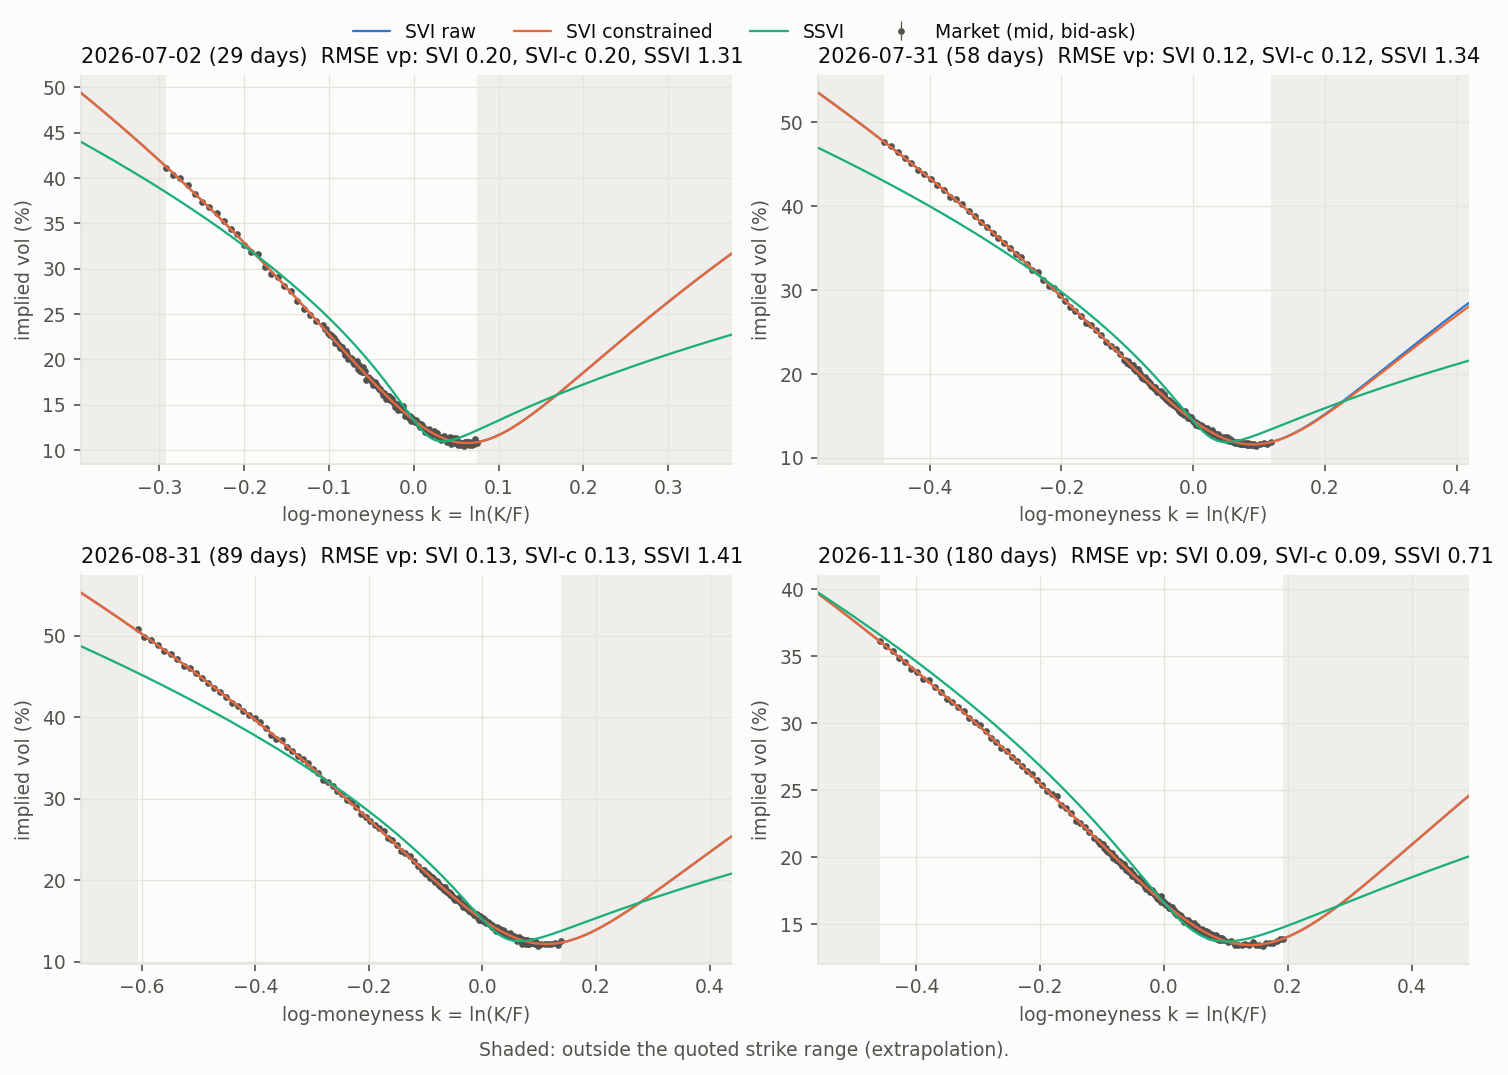

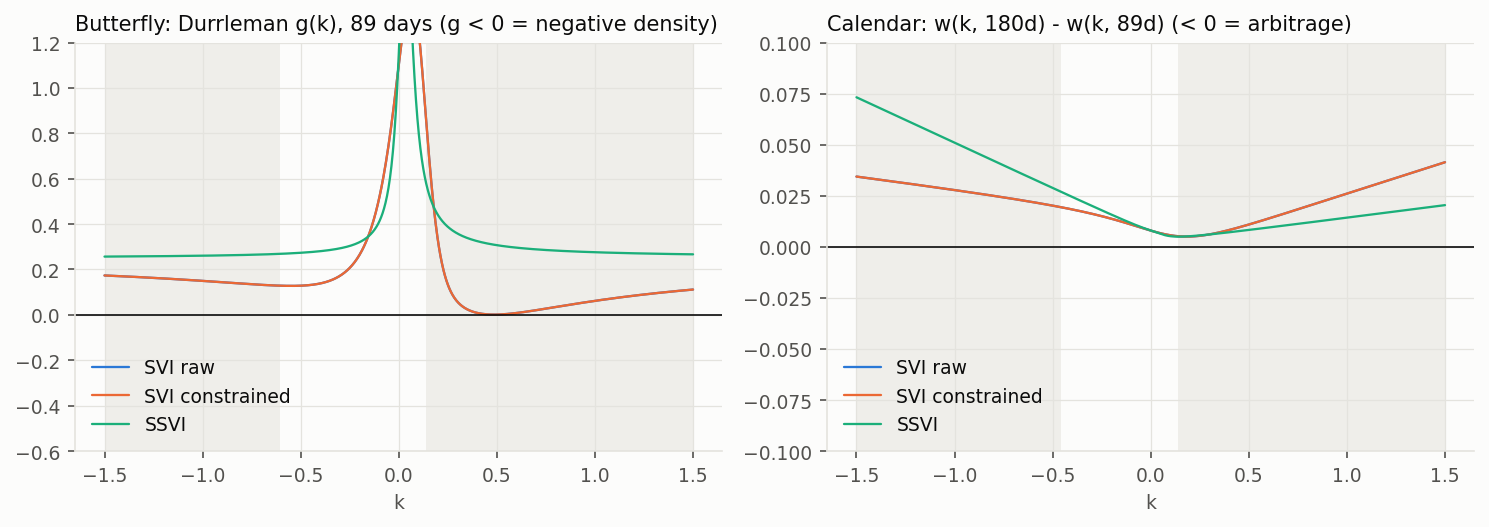

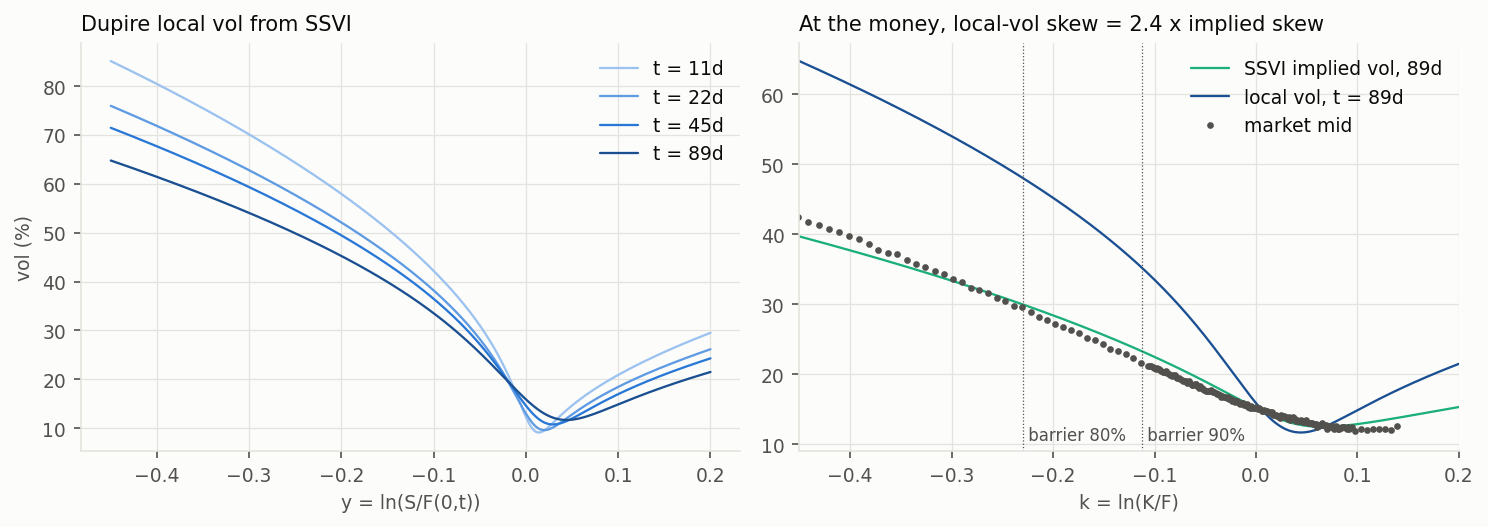

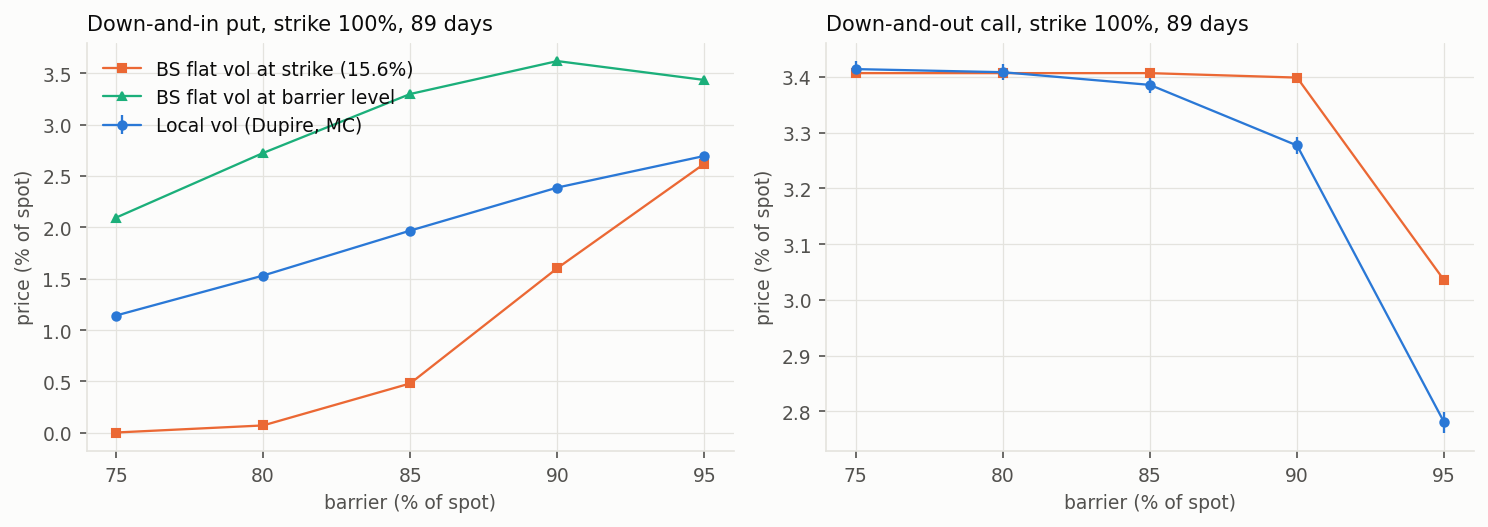

Notebook ran in 17 s


In [6]:
figs = plot_all(res, ROOT / "out" / "demo_figures")
for f in figs:
    display(Image(filename=str(f)))
print(f"Notebook ran in {time.perf_counter() - t_start:.0f} s")